# Ocean Acidification: pH

Projected surface ocean pH near the selected site from two sources: CMIP6 members of the IPCC-WGI AR6 Interactive Atlas (global warming levels) and the decadal carbonate-system projections of Jiang et al. (2023) (spatial context).

```{glue:figure} ph_box_fig
:scale: 60%
:align: right
```

**Figure. Surface pH at global warming levels.** Each box shows the spread across CMIP6 members in the year each scenario first reaches the level.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Projection plotting utilities come from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository (`ind_setup.plotting_projections`); data access, site configuration and output helpers come from `functions/projections.py` and `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
from ind_setup.plotting_projections import plot_projection_palau, get_box_data, plot_global_warming_boxplot, plot_timeseries_with_mini_maps

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


### Scenarios and global warming levels

Years at which the IPCC AR6 multi-model mean global surface temperature first reaches each warming level (°C above 1850–1900), computed in [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb). Local values are read from every model at those years.

In [5]:
ssp_scenarios = ['ssp245', 'ssp370', 'ssp585']
incr_temps = list(prj.WARMING_LEVELS)
delta_t = 0  # warming levels are already expressed relative to 1850–1900

scenario_info = prj.load_warming_levels(ssp_scenarios)
pd.DataFrame({sc: {f"+{wl}°C": info["year"] for wl, info in levels.items()} for sc, levels in scenario_info.items()})

,ssp245,ssp370,ssp585
+1.5°C,2030-01-01,2030-01-01,2027-01-01
+2.0°C,2052-01-01,2046-01-01,2041-01-01
+2.5°C,2079-01-01,2061-01-01,2053-01-01
+3.0°C,NaT,2075-01-01,2064-01-01


### Get data

Monthly surface pH of the CMIP6 ensemble from the [IPCC-WGI AR6 Interactive Atlas](https://interactive-atlas.ipcc.ch/) (`data_copernicus/monthly_mean_of_acidity_of_seawater_*`), averaged to annual means at the ocean cell nearest to the site and cached under `data/projections/<site_tag>/`.

In [6]:
ds = prj.extract_atlas_ph_point(site_lon, site_lat, ssp_scenarios, cache_file=cache_dir / "ph_point.nc")
print(f"Grid cell used: lon {ds.attrs['grid_lon']}, lat {ds.attrs['grid_lat']}")

Grid cell used: lon 134.5, lat 6.5


## Analysis

### Projected pH

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_ph_timeseries_palau_psw00040309_lat7p337_lon134p477.png')

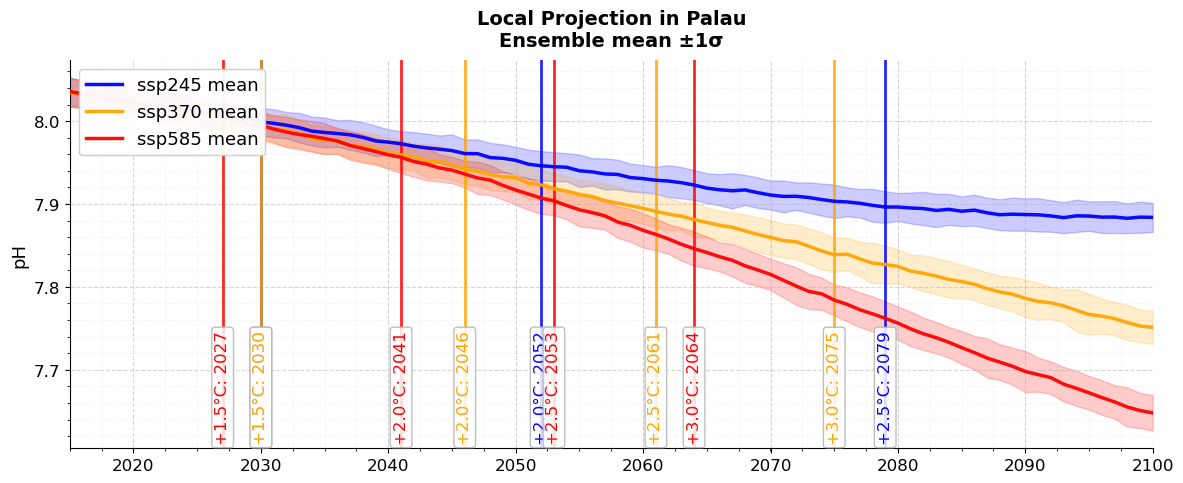

In [7]:
fig, ax = plot_projection_palau(ds, "ph", scenario_info, ssp_scenarios, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "ph_timeseries", site_tag)

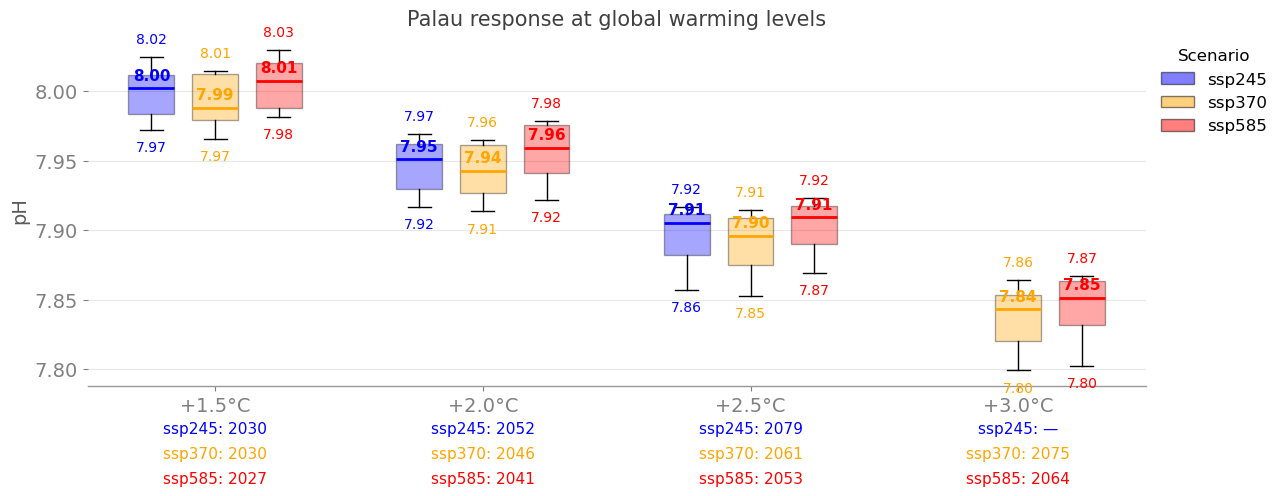

In [8]:
box_data, box_scenarios, positions = get_box_data(ds, scenario_info, incr_temps, ssp_scenarios, "ph")
fig, ax = plot_global_warming_boxplot(box_data, ds, positions, box_scenarios, scenario_info, incr_temps, "ph",
                                      plot_ref=False, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "ph_gwl", site_tag)
glue("ph_box_fig", fig, display=False)

In [9]:
table = prj.gwl_summary(ds, "ph", scenario_info, ssp_scenarios, decimals=3)
prj.save_table(table, tables_dir, "ph_gwl", site_tag)
table

,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,SSP245,+1.5°C,2030,10,8.002,7.981,8.019,7.972,8.025
1,SSP245,+2.0°C,2052,10,7.951,7.927,7.965,7.917,7.969
2,SSP245,+2.5°C,2079,10,7.906,7.873,7.913,7.857,7.917
3,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,SSP370,+1.5°C,2030,9,7.988,7.970,8.014,7.966,8.014
5,SSP370,+2.0°C,2046,9,7.943,7.922,7.962,7.914,7.965
6,SSP370,+2.5°C,2061,9,7.896,7.870,7.911,7.853,7.915
7,SSP370,+3.0°C,2075,9,7.843,7.815,7.858,7.799,7.864
8,SSP585,+1.5°C,2027,10,8.008,7.987,8.024,7.981,8.030
9,SSP585,+2.0°C,2041,10,7.959,7.934,7.978,7.922,7.979


### Surface ocean carbonate system

Decadal projections of the surface ocean carbonate system on a 1° grid (median and standard deviation of the CMIP6 Earth system models; [Jiang et al., 2023](https://www.ncei.noaa.gov/data/oceans/ncei/ocads/metadata/0259391.html), NOAA NCEI OCADS 0259391). The site value is read at the nearest ocean cell; the mini maps show a ±7° window around it.

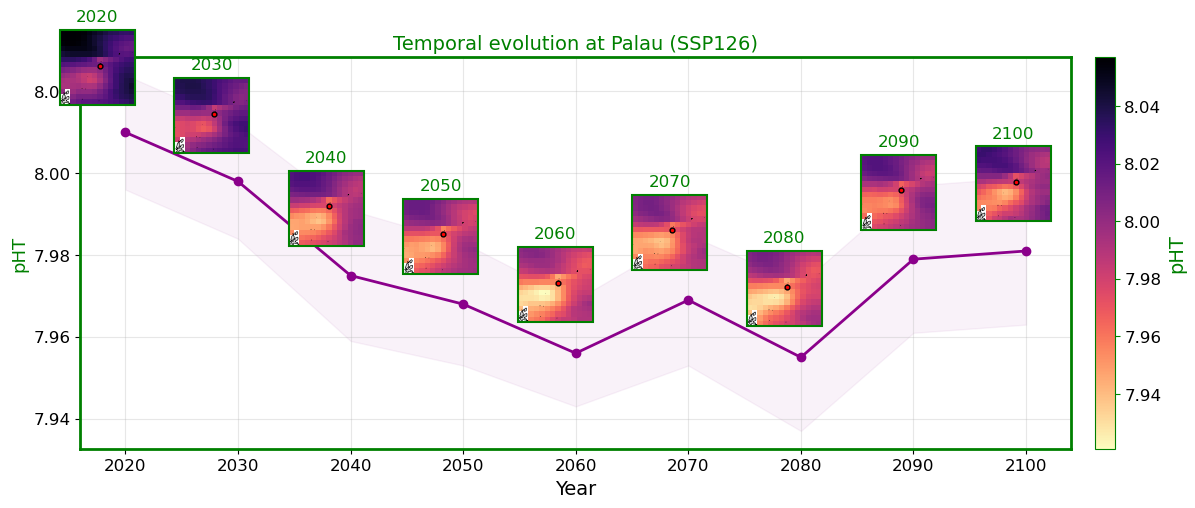

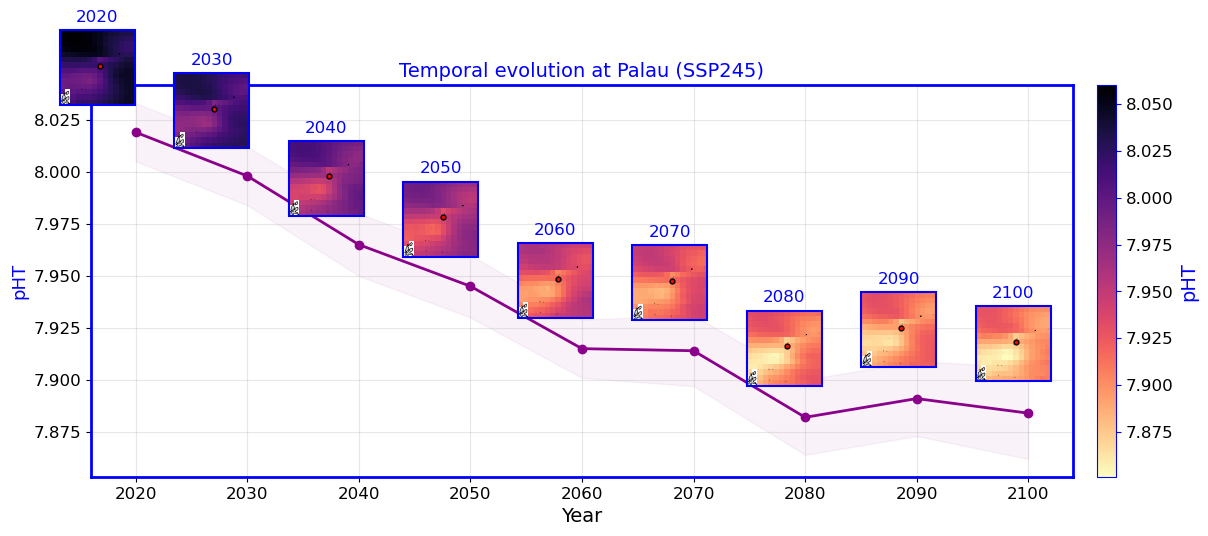

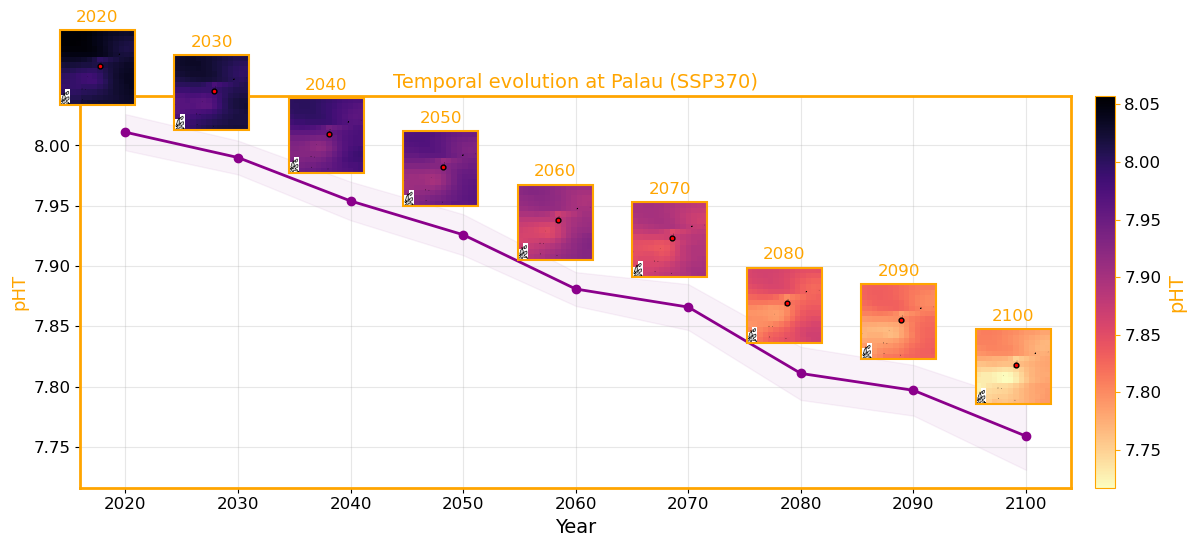

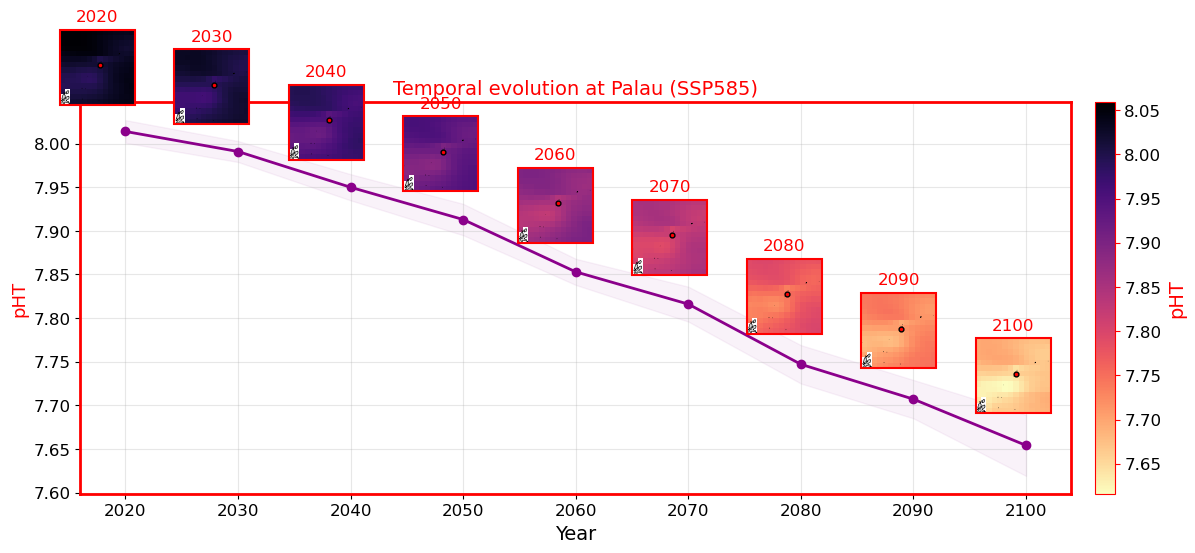

In [10]:
ocads_scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]

for scenario in ocads_scenarios:
    point, point_std, area = prj.ocads_site("pHT", scenario, site_lon, site_lat)
    fig = plot_timeseries_with_mini_maps(area, point, point_std, scenario=scenario, var_analysis="pHT",
                                         lon_lat=[site_lon % 360, site_lat], cmap='magma_r', c_line="darkmagenta",
                                         site_label=site_label)
    prj.save_figure(fig, fig_dir, f"ph_maps_timeseries_{scenario}", site_tag)
    if scenario == "ssp245":
        glue("ph_maps_fig", fig, display=False)

In [11]:
table = prj.ocads_table("pHT", ocads_scenarios, site_lon, site_lat)
prj.save_table(table, tables_dir, "ph_ocads_decadal", site_tag, index=True)
table

,SSP126 median,SSP126 std,SSP245 median,SSP245 std,SSP370 median,SSP370 std,SSP585 median,SSP585 std
Year,,,,,,,,
2020,8.010,0.014,8.019,0.014,8.011,0.015,8.014,0.013
2030,7.998,0.014,7.998,0.014,7.990,0.014,7.991,0.012
2040,7.975,0.016,7.965,0.015,7.954,0.016,7.950,0.015
2050,7.968,0.015,7.945,0.015,7.926,0.017,7.913,0.018
2060,7.956,0.013,7.915,0.014,7.881,0.014,7.853,0.015
2070,7.969,0.016,7.914,0.017,7.866,0.019,7.816,0.020
2080,7.955,0.018,7.882,0.018,7.811,0.022,7.747,0.022
2090,7.979,0.018,7.891,0.018,7.797,0.021,7.707,0.022
2100,7.981,0.018,7.884,0.022,7.759,0.028,7.654,0.035
